# Sujet 04 Allstate : P3
**Nom :** HOUNGBO Gwenaël · **Porteur :** P3 · **Étapes assignées :** 1-6 Trous → 1-4 Cardinalité → 1-9 Cibles

Chaque section se termine par une cellule *Conclusion* à rédiger avec tes propres mots à partir des résultats.

## 0. Chargement

In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("data")
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "a_estimer.csv")
print(train.shape, test.shape)   # attendu : (150654, 132) (37664, 131)

(150654, 132) (37664, 131)


In [2]:
cat_cols = [c for c in train.columns if c.startswith("cat")]
cont_cols = [c for c in train.columns if c.startswith("cont")]
print(len(cat_cols), len(cont_cols))   # attendu : 116 14

116 14


## 1-6 Trous
Trois contrôles : NaN officiels, trous déguisés dans les catégorielles, zéros suspects dans les continues.

In [3]:
print("NaN train :", train.isna().sum().sum())
print("NaN test  :", test.isna().sum().sum())

NaN train : 0
NaN test  : 0


In [4]:
masques = ["", " ", "?", "NA", "N/A", "nan", "null", "None", "-"]
for c in cat_cols:
    n = train[c].isin(masques).sum()
    if n > 0:
        print(c, n)
print("contrôle des masques terminé")

contrôle des masques terminé


In [5]:
for c in cont_cols:
    part = (train[c] == 0).mean()
    if part > 0.01:
        print(c, round(part, 3))
print("contrôle des zéros terminé")

contrôle des zéros terminé


**Conclusion 1-6** *(à rédiger)* :

> Aucune valeur manquante, vérifiée de trois façons : ...

## 1-4 Cardinalité
Nombre de modalités distinctes par variable catégorielle.

In [6]:
card = train[cat_cols].nunique().sort_values(ascending=False)
print("min :", card.min(), "| max :", card.max())
card.head(10)

min : 2 | max : 317


cat116    317
cat110    130
cat109     80
cat113     61
cat112     51
cat115     23
cat105     20
cat107     20
cat114     19
cat101     18
dtype: int64

In [7]:
print("one-hot complet :", card.sum(), "colonnes")
print("variables > 255 modalités :", (card > 255).sum())

one-hot complet : 1123 colonnes
variables > 255 modalités : 1


In [8]:
inconnues = 0
for c in cat_cols:
    absentes = set(test[c].unique()) - set(train[c].unique())
    inconnues += len(absentes)
print("modalités du test absentes du train :", inconnues)

modalités du test absentes du train : 16


**Conclusion 1-4** *(à rédiger)* :

> Les 116 variables ont de ... à ... modalités. Un one-hot complet donnerait ... colonnes. ... variable(s) dépasse(nt) 255 modalités. Le test contient ... modalité(s) inconnue(s) du train.

## 1-9 La cible : `loss`

In [9]:
y = train["loss"]
print("NaN :", y.isna().sum(), "| valeurs <= 0 :", (y <= 0).sum())
print("min :", round(y.min(), 2), "| max :", round(y.max()))
print("moyenne :", round(y.mean(), 2), "| médiane :", round(y.median(), 2))
print("asymétrie :", round(y.skew(), 2))

NaN : 0 | valeurs <= 0 : 0
min : 0.67 | max : 121012
moyenne : 3038.92 | médiane : 2115.57
asymétrie : 3.93


In [10]:
y.quantile([0.01, 0.1, 0.5, 0.9, 0.99, 0.999]).round()

0.010      391.0
0.100      775.0
0.500     2116.0
0.900     6402.0
0.990    14026.0
0.999    24365.0
Name: loss, dtype: float64

In [11]:
mae_moyenne = (y - y.mean()).abs().mean()
mae_mediane = (y - y.median()).abs().mean()
print("MAE en annonçant la moyenne :", round(mae_moyenne, 2))   # énoncé : 1807,09
print("MAE en annonçant la médiane :", round(mae_mediane, 2))
print("gain de la médiane :", round(1 - mae_mediane / mae_moyenne, 3))   # énoncé : 8,9 %

MAE en annonçant la moyenne : 1968.14
MAE en annonçant la médiane : 1810.49
gain de la médiane : 0.08


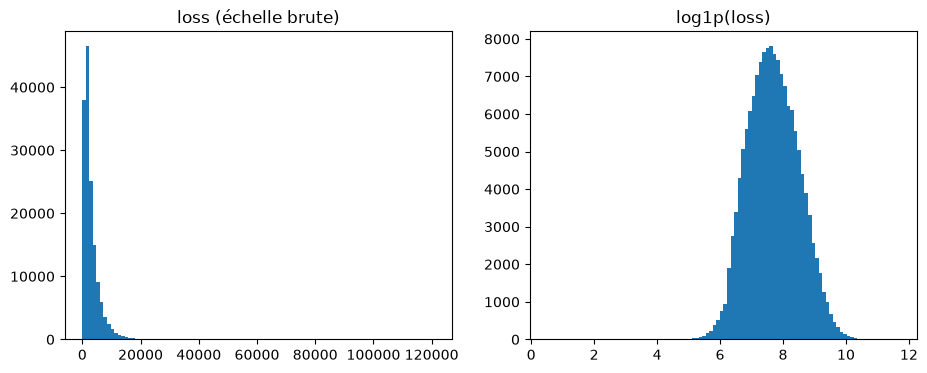

In [12]:
# Nécessite : pip install matplotlib
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(y, bins=100)
ax[0].set_title("loss (échelle brute)")
ax[1].hist(np.log1p(y), bins=100)
ax[1].set_title("log1p(loss)")
plt.show()

**Conclusion 1-9** *(à rédiger)* :

> La cible va de ... à ..., médiane ..., moyenne ..., fortement asymétrique (skewness ...). Annoncer la médiane plutôt que la moyenne fait gagner ... % de MAE.

## 1-12 Coût des erreurs *(attribué à P4 : à coordonner avec l'équipe)*

In [13]:
erreur = y - y.median()
sous = erreur[erreur > 0]
sur = -erreur[erreur < 0]
print("sous-estimations :", len(sous), "| moyenne :", round(sous.mean(), 2), "| total :", round(sous.sum()))
print("surestimations   :", len(sur), "| moyenne :", round(sur.mean(), 2), "| total :", round(sur.sum()))
print("plus grosse sous-estimation :", round(sous.max()))
print("plus grosse surestimation   :", round(sur.max()))

sous-estimations : 75327 | moyenne : 2733.84 | total : 205931880
surestimations   : 75327 | moyenne : 887.13 | total : 66825089
plus grosse sous-estimation : 118897
plus grosse surestimation   : 2115


In [14]:
for k in [1, 2, 3]:
    tau = k / (1 + k)
    c = y.quantile(tau)
    cout = (k * (y - c).clip(lower=0) + (c - y).clip(lower=0)).mean()
    print("k =", k, "| constante :", round(c), "| coût moyen :", round(cout, 2))

k = 1 | constante : 2116 | coût moyen : 1810.49
k = 2 | constante : 3099 | coût moyen : 2951.44
k = 3 | constante : 3866 | coût moyen : 3794.29
